# Imports and data function

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

In [3]:
def DNBR_extraction_function(filename):
    # Read the COBRA output file
    with open(filename, 'r') as file:
        lines = file.readlines()

    # Find the beginning of the temperature data section
    start = next(
        i for i, line in enumerate(lines)
        if 'TEMPERATURE DATA FOR ROD' in line
    )

    # Extract the numerical data
    data = []

    for line in lines[start+1:]:
        values = line.split()

        if len(values) >= 3:
            try:
                distance = float(values[0])
                dnbr = float(values[2])
                data.append([distance, dnbr])
            except ValueError:
                # Stop once we reach the end of the data table
                if data:
                    break

    # Convert into NumPy arrays
    data = np.array(data)

    distance = data[:, 0]
    dnbr = data[:, 1]

    # Find the first non-zero DNBR value
    first_valid = np.flatnonzero(dnbr != 0)[0]

    # Slice both arrays from that position
    distance = distance[first_valid:]
    dnbr = dnbr[first_valid:]

    return distance, dnbr

In [4]:
distance_control, DNBR_control = DNBR_extraction_function('PWR_INP_1_1.txt.out')

distance_F1750, DNBR_F1750 = DNBR_extraction_function('PWR_INP_1_4_1750_563.txt.out')
distance_F3000, DNBR_F3000 = DNBR_extraction_function('PWR_INP_1_4_3000_563.txt.out')

distance_T573, DNBR_T573 = DNBR_extraction_function('PWR_INP_1_4_3876_573.txt.out')
distance_T588, DNBR_T588 = DNBR_extraction_function('PWR_INP_1_4_3876_588.txt.out')

# Plotting Temperatures

In [5]:
from matplotlib.lines import Line2D
from matplotlib.colors import to_rgba
from matplotlib.legend_handler import HandlerTuple

color_list = ["#D55E00", "#0072B2", "#009E73"]
marker_list = ["o", "D", "s"]

labels_temperature = ["T = 563 K",
                      "T = 573 K",
                      "T = 588 K"]

temperature_legend_elements = []

for color, marker, label in zip(color_list, marker_list, labels_temperature):

    line = Line2D(
        [0], [0],
        color=to_rgba(color, 0.3),
        linestyle='none',
        linewidth=1.5
    )

    marker_handle = Line2D(
        [0], [0],
        color=color,
        marker=marker,
        linestyle='None',
        markerfacecolor='none',
        markeredgecolor=color,
        markersize=5
    )

    temperature_legend_elements.append(((line, marker_handle), label))

labels_flux = ["F = 3876 kg/m$^2$ s",
               "F = 1750 kg/m$^2$ s",
               "T = 3000 kg/m$^2$ s"]

flux_legend_elements = []

for color, marker, label in zip(color_list, marker_list, labels_flux):

    line = Line2D(
        [0], [0],
        color=to_rgba(color, 0.3),
        linestyle='none',
        linewidth=1.5
    )

    marker_handle = Line2D(
        [0], [0],
        color=color,
        marker=marker,
        linestyle='None',
        markerfacecolor='none',
        markeredgecolor=color,
        markersize=5
    )

    flux_legend_elements.append(((line, marker_handle), label))

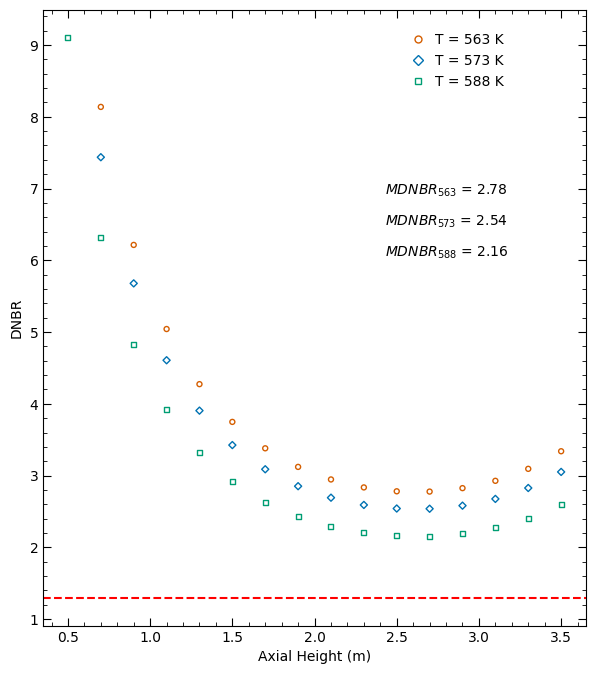

In [6]:
#######
# Setup
#######

fig = plt.figure(figsize=(7, 8))

gs = fig.add_gridspec(
    1, 1,
    # height_ratios=[5, 2],
    # hspace=0
)

ax_main = fig.add_subplot(gs[0])
# ax_res = fig.add_subplot(gs[1])


###########
# Main Plot
###########

for xdata, ydata, color, marker in zip([distance_control, distance_T573, distance_T588], [DNBR_control, DNBR_T573, DNBR_T588],
                                       color_list, marker_list):
    ax_main.scatter(xdata, ydata,
                    color = color, marker = marker, facecolor = "none", s = 13)


ax_main.legend(
    handles=[item[0] for item in temperature_legend_elements],
    labels=[item[1] for item in temperature_legend_elements],
    handler_map={tuple: HandlerTuple(ndivide=None)},
    loc="upper left",
    bbox_to_anchor=(0.63, 0.98),
    borderpad=0.3,
    facecolor="white",
    edgecolor="white",
    framealpha=1
)

ax_main.text(
    0.63, 0.7,
    rf"$MDNBR_{{563}}$ = {np.min(DNBR_control):.2f}",
    transform=ax_main.transAxes,
    color="black",
    fontsize=10
)

ax_main.text(
    0.63, 0.65,
    rf"$MDNBR_{{573}}$ = {np.min(DNBR_T573):.2f}",
    transform=ax_main.transAxes,
    color="black",
    fontsize=10
)

ax_main.text(
    0.63, 0.6,
    rf"$MDNBR_{{588}}$ = {np.min(DNBR_T588):.2f}",
    transform=ax_main.transAxes,
    color="black",
    fontsize=10
)

ax_main.axhline(1.3, color = "red", linestyle = "--")


#####################
# Formatting and Save
#####################

ax_main.set_ylabel("DNBR")
ax_main.set_xlabel("Axial Height (m)")

for ax in [ax_main]:
    ax.minorticks_on()
    ax.tick_params(which='major', size=6, direction='in',
                   right=True, top=True)
    ax.tick_params(which='minor', size=3, direction='in',
                   right=True, top=True)
    for label in ax.get_xticklabels() + ax.get_yticklabels():
        label.set_bbox(dict(
            facecolor="white",
            edgecolor="none",
            pad=1.0
        ))

plt.savefig(
    r"C:\Users\sebas\Documents\Cambridge\NE2 Reactor Engineering\COBRA Project\Plots\PWR_1_4_Temperature_Plot.png",
    dpi=250,
    bbox_inches="tight"
)

plt.show()

# Flux Plot

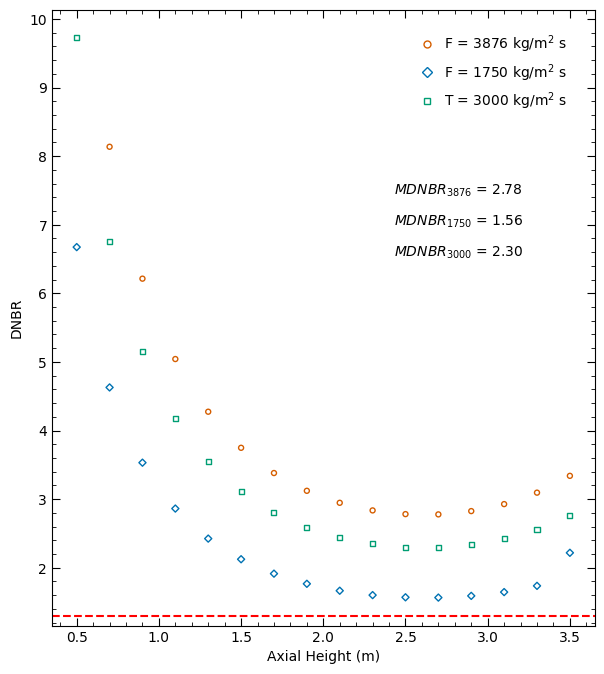

In [7]:
#######
# Setup
#######

fig = plt.figure(figsize=(7, 8))

gs = fig.add_gridspec(
    1, 1,
    # height_ratios=[5, 2],
    # hspace=0
)

ax_main = fig.add_subplot(gs[0])
# ax_res = fig.add_subplot(gs[1])


###########
# Main Plot
###########

for xdata, ydata, color, marker in zip([distance_control, distance_F1750, distance_F3000], [DNBR_control, DNBR_F1750, DNBR_F3000],
                                       color_list, marker_list):
    ax_main.scatter(xdata, ydata,
                    color = color, marker = marker, facecolor = "none", s = 13)


ax_main.text(
    0.63, 0.7,
    rf"$MDNBR_{{3876}}$ = {np.min(DNBR_control):.2f}",
    transform=ax_main.transAxes,
    color="black",
    fontsize=10
)

ax_main.text(
    0.63, 0.65,
    rf"$MDNBR_{{1750}}$ = {np.min(DNBR_F1750):.2f}",
    transform=ax_main.transAxes,
    color="black",
    fontsize=10
)

ax_main.text(
    0.63, 0.6,
    rf"$MDNBR_{{3000}}$ = {np.min(DNBR_F3000):.2f}",
    transform=ax_main.transAxes,
    color="black",
    fontsize=10
)


ax_main.legend(
    handles=[item[0] for item in flux_legend_elements],
    labels=[item[1] for item in flux_legend_elements],
    handler_map={tuple: HandlerTuple(ndivide=None)},
    loc="upper left",
    bbox_to_anchor=(0.63, 0.98),
    borderpad=0.3,
    facecolor="white",
    edgecolor="white",
    framealpha=1
)

ax_main.axhline(1.3, color = "red", linestyle = "--")


#####################
# Formatting and Save
#####################

ax_main.set_ylabel("DNBR")
ax_main.set_xlabel("Axial Height (m)")

for ax in [ax_main]:
    ax.minorticks_on()
    ax.tick_params(which='major', size=6, direction='in',
                   right=True, top=True)
    ax.tick_params(which='minor', size=3, direction='in',
                   right=True, top=True)
    for label in ax.get_xticklabels() + ax.get_yticklabels():
        label.set_bbox(dict(
            facecolor="white",
            edgecolor="none",
            pad=1.0
        ))

plt.savefig(
    r"C:\Users\sebas\Documents\Cambridge\NE2 Reactor Engineering\COBRA Project\Plots\PWR_1_4_Flux_Plot.png",
    dpi=250,
    bbox_inches="tight"
)

plt.show()